# 3 — Fresh cue-only CEBRA-Time and matched references
Independent source reconstruction; no old encoder, standardized array or notebook cache. Existing offset1-model/temperature1/Adam and exact row-uniform native-adjacent-bin Time sampler. Public demo uses20updates; reviewed biological configuration requires1000, unchanged.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from neuro.notebook_inputs import configuration_from_environment, inspect_inputs, load_inputs, effective_pair_map
from neuro.pseudopopulation import sample_plan, materialize, support
from neuro.notebook_artifacts import ArtifactStore, FitAccounting, target_heads, write_private_json, verify_artifacts, runtime_identity, validate_kernel_identity
from neuro.notebook_support import workspace, usage_summary, source_budget, checked_assemblies, compact_metrics, plot_confusions

configuration = configuration_from_environment()
settings = configuration['execution']
output = workspace()
def private_warning(message, category, filename, lineno, file=None, line=None):
    # Preserve full provenance privately; do not render host paths in shared figures/output.
    warning_path = output / 'warnings-private.jsonl'
    with warning_path.open('a') as handle:
        handle.write(json.dumps({'message': str(message), 'category': category.__name__, 'filename': filename, 'lineno': lineno}) + '\n')
    warning_path.chmod(0o600)
    print(category.__name__ + ': ' + str(message), file=sys.stderr)
warnings.showwarning = private_warning
store = ArtifactStore(output / 'artifacts')
store.save('configuration', configuration)
store.save('kernel_runtime_before_inputs', validate_kernel_identity(configuration))
print('Input mode:', configuration['mode'], '| exploratory computational assay; no biological IID inference')

Input mode: invented | exploratory computational assay; no biological IID inference


## Explicit metadata and target boundary
Authenticate only supplied files, regenerate eligibility/assignments, freeze the contributor embargo and complete-support panel before neural interpretation. The public default is invented data. Missing supplied inputs fail; no demo or historical-result fallback.

In [2]:
inspection = inspect_inputs(configuration)  # Metadata/hash step only for supplied inputs.
store.save('metadata_selection', inspection)  # Protected provenance; never displayed.
print(json.dumps(inspection.audit, sort_keys=True))
assert inspection.audit['contributor_overlap'] == 0
assert inspection.audit['selected_train'] > 0 and inspection.audit['selected_development'] > 0

{"access": "invented fixture; no biological input files", "contributor_overlap": 0, "eligible": 216, "embargo_removed_train": 0, "exclusion_counts": {}, "original_development": 72, "original_sessions": 3, "original_train": 144, "original_units": 9, "selected_development": 72, "selected_sessions": 3, "selected_train": 144, "selected_units": 9, "surviving_train": 144}


In [3]:
data, neural_audit = load_inputs(inspection)  # Supplied neural path remains explicitly review-gated.
store.save('source_data', data)
store.save('neural_audit', neural_audit)
print(json.dumps(neural_audit, sort_keys=True))
assert np.isfinite(data.values[data.observed]).all()
assert np.isnan(data.values[~data.observed]).all()
assert not data.dependency_audit()['overlapping_contributor_ids']
print('Source × unit × bin shape:', data.values.shape, '| units:', data.value_unit, '| clock units:', data.time_unit)

{"access": "fresh invented count generation", "full_exposure": true, "observed_values": 2592, "unavailable_values": 5184}
Source × unit × bin shape: (216, 9, 4) | units: count | clock units: s


## Declare optimization, temporal pairs and worlds
The permutation shuffles joint pair labels at source level within block×split before matching. It preserves observed provenance and uses its own fixed development world. It is an alignment-breaking diagnostic, not a statistical null.

In [4]:
import neuro.cebra as cebra
validate_kernel_identity(configuration)  # Includes actual optional dependency origins/code before fitting.
from neuro.pca_lda import fit_standardizer, raw_features, fit_pca
from neuro.notebook_support import fit_logistic
assert settings['seeds'] == [0, 1]
print({k: settings[k] for k in ('iterations', 'batch_size', 'hidden', 'output_dimension', 'learning_rate')})
print('Native positives:', [[b, b + 1] for b in range(data.values.shape[2] - 1)], '| references row-uniform; negatives row/bin-uniform')
accounting = FitAccounting(cebra=True).start()
results = []

{'iterations': 20, 'batch_size': 32, 'hidden': 32, 'output_dimension': 8, 'learning_rate': 0.0003}
Native positives: [[0, 1], [1, 2], [2, 3]] | references row-uniform; negatives row/bin-uniform


## Visible fresh encoder, reference and readout fits
Every source-budget/world/seed refits normalization, PCA, CEBRA and three separate logistic heads. Development transformations cannot refit. Paired seeds do not represent biological replication.

observed_seed0_full source accounting: {"eligible_sources": 144, "repeated_sources": 41, "reuse_histogram": {"0": 49, "1": 54, "2": 34, "3": 6, "4": 1}, "unused_sources": 49, "used_sources": 95}


[{"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": "pair", "log_loss": 1.4472202746403922, "macro_F1": 0.5244708994708994, "name": "observed_seed0_full_raw_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.4375}, {"accuracy": 0.5833333333333334, "development_BA": 0.5833333333333334, "head": "start", "log_loss": 0.934599828772277, "macro_F1": 0.5777777777777778, "name": "observed_seed0_full_raw_start", "train_BA": 0.9583333333333334, "train_development_gap": 0.375}, {"accuracy": 0.5833333333333334, "development_BA": 0.5833333333333334, "head": "goal", "log_loss": 0.9382765802010958, "macro_F1": 0.5874183006535948, "name": "observed_seed0_full_raw_goal", "train_BA": 0.9166666666666666, "train_development_gap": 0.33333333333333326}, {"accuracy": 0.4583333333333333, "development_BA": 0.4583333333333333, "head": "pair", "log_loss": 1.5421393198985764, "macro_F1": 0.45171957671957674, "name": "observed_seed0_full_pca_pair", "train_BA": 0.958333333

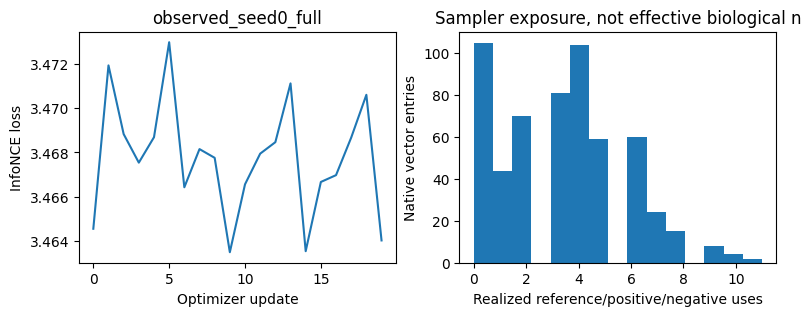

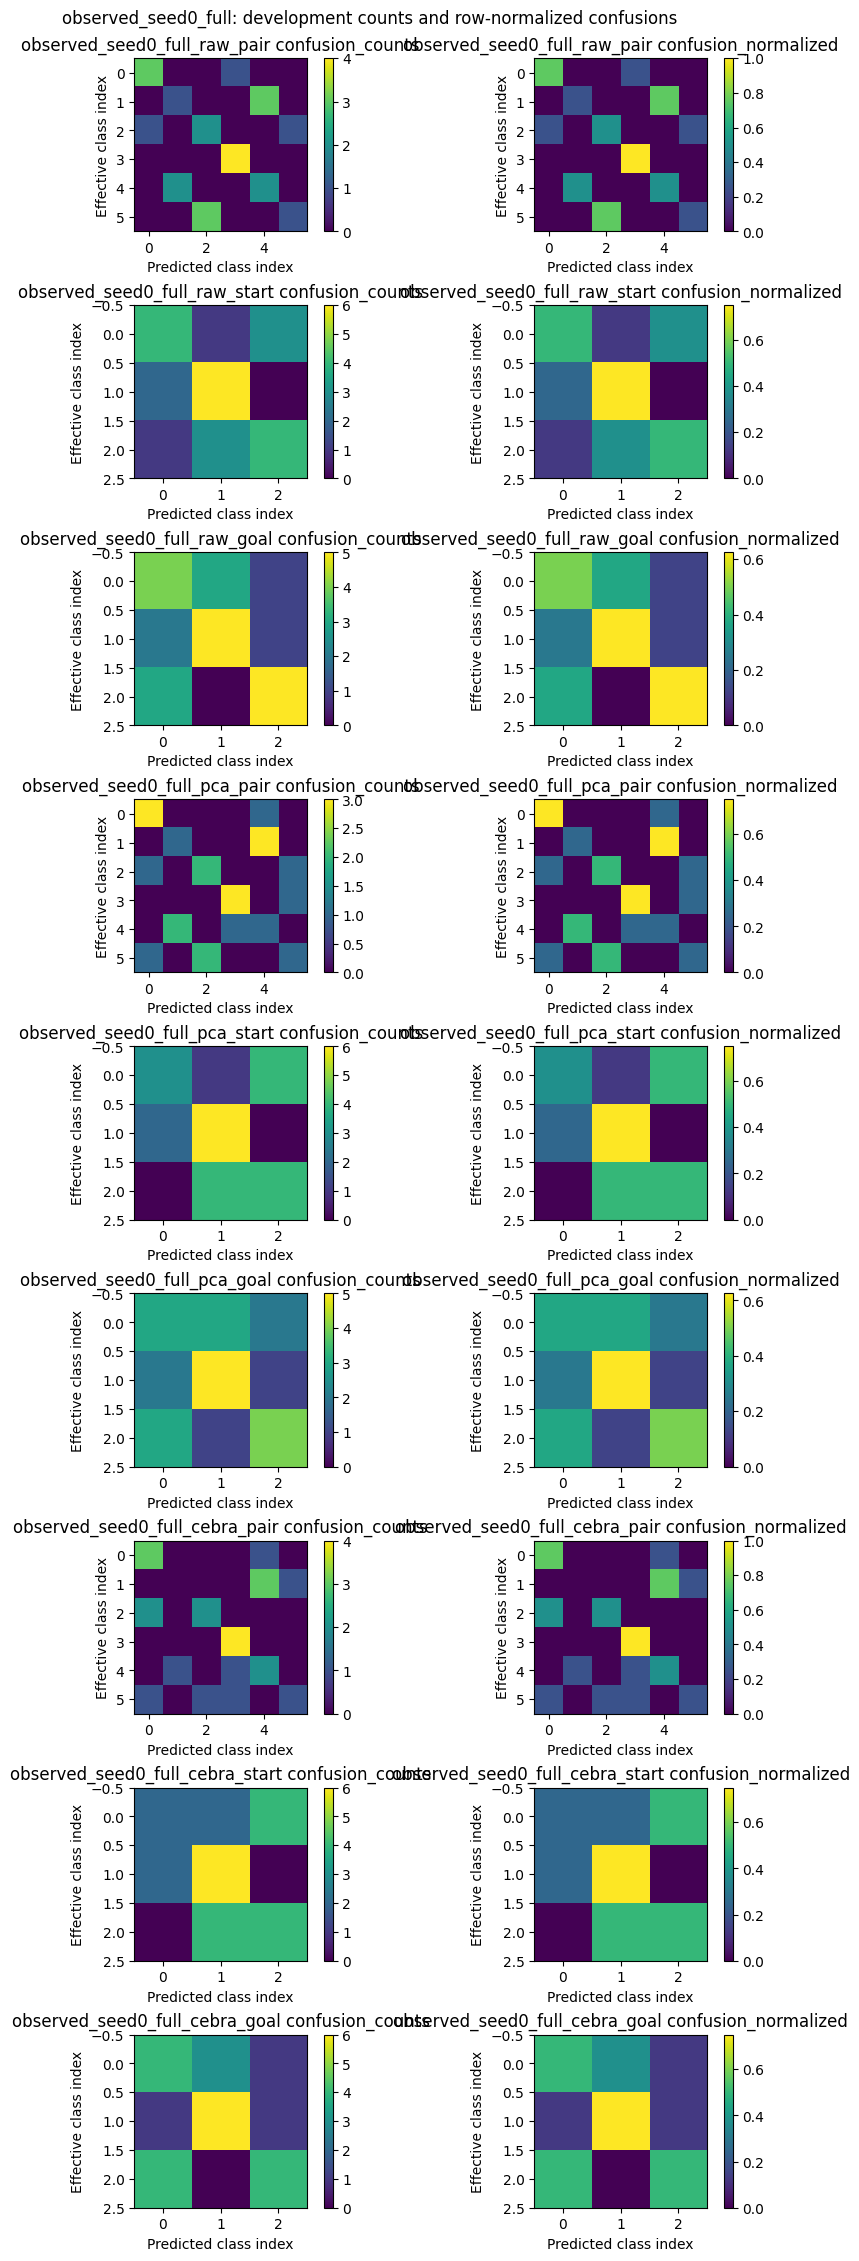

observed_seed0_reduced source accounting: {"eligible_sources": 72, "repeated_sources": 45, "reuse_histogram": {"0": 5, "1": 22, "2": 19, "3": 21, "4": 4, "5": 1}, "unused_sources": 5, "used_sources": 67}


[{"accuracy": 0.6666666666666666, "development_BA": 0.6666666666666666, "head": "pair", "log_loss": 1.4307729482725293, "macro_F1": 0.6549422799422799, "name": "observed_seed0_reduced_raw_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.3125}, {"accuracy": 0.5, "development_BA": 0.5, "head": "start", "log_loss": 0.9870779302306308, "macro_F1": 0.49807273336685104, "name": "observed_seed0_reduced_raw_start", "train_BA": 0.9166666666666666, "train_development_gap": 0.41666666666666663}, {"accuracy": 0.5, "development_BA": 0.5, "head": "goal", "log_loss": 0.9432951435883173, "macro_F1": 0.48888888888888893, "name": "observed_seed0_reduced_raw_goal", "train_BA": 0.9375, "train_development_gap": 0.4375}, {"accuracy": 0.6666666666666666, "development_BA": 0.6666666666666666, "head": "pair", "log_loss": 1.5056552276527686, "macro_F1": 0.6494708994708994, "name": "observed_seed0_reduced_pca_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.3125}, {"accuracy": 0

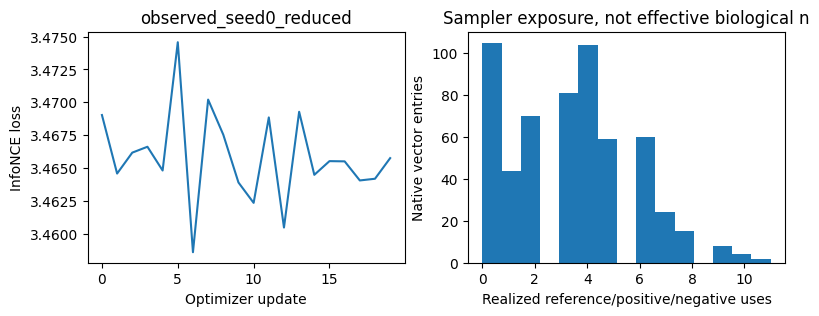

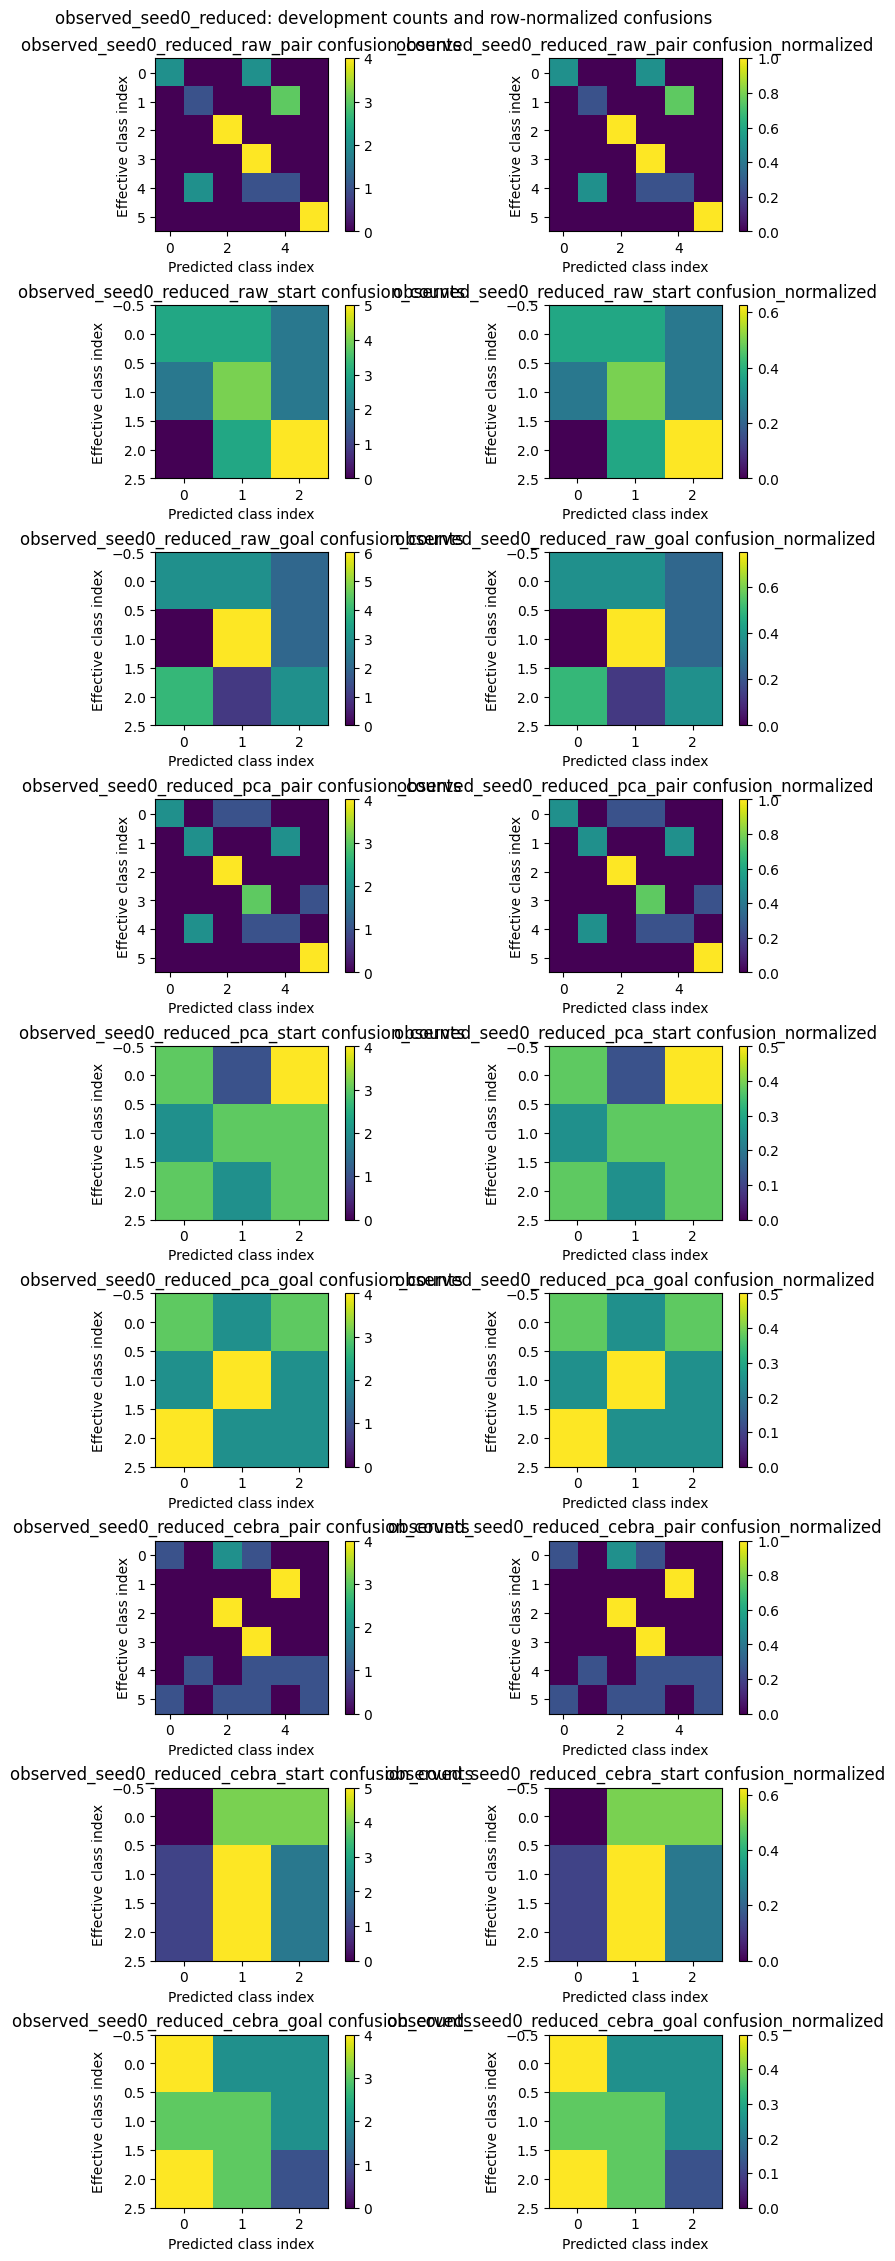

observed_seed1_full source accounting: {"eligible_sources": 144, "repeated_sources": 41, "reuse_histogram": {"0": 51, "1": 52, "2": 33, "3": 6, "4": 2}, "unused_sources": 51, "used_sources": 93}


[{"accuracy": 0.6666666666666666, "development_BA": 0.6666666666666666, "head": "pair", "log_loss": 1.4675189499421784, "macro_F1": 0.6438672438672438, "name": "observed_seed1_full_raw_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.3125}, {"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": "start", "log_loss": 0.9640804543020621, "macro_F1": 0.5376180836707153, "name": "observed_seed1_full_raw_start", "train_BA": 0.9791666666666666, "train_development_gap": 0.4375}, {"accuracy": 0.4583333333333333, "development_BA": 0.4583333333333333, "head": "goal", "log_loss": 1.0136190653937938, "macro_F1": 0.44674818359028884, "name": "observed_seed1_full_raw_goal", "train_BA": 0.9583333333333334, "train_development_gap": 0.5}, {"accuracy": 0.4583333333333333, "development_BA": 0.4583333333333333, "head": "pair", "log_loss": 1.581541805526027, "macro_F1": 0.41630591630591623, "name": "observed_seed1_full_pca_pair", "train_BA": 0.9791666666666666, "trai

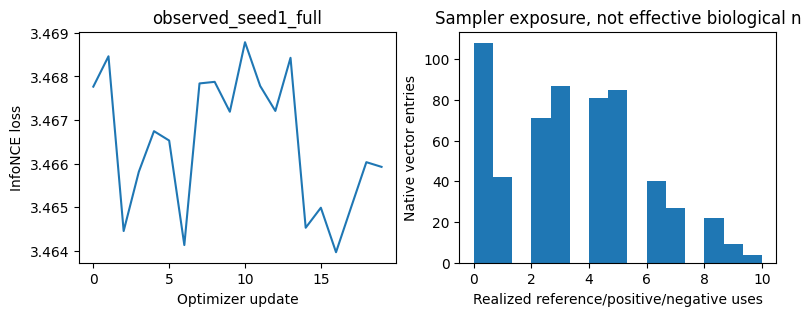

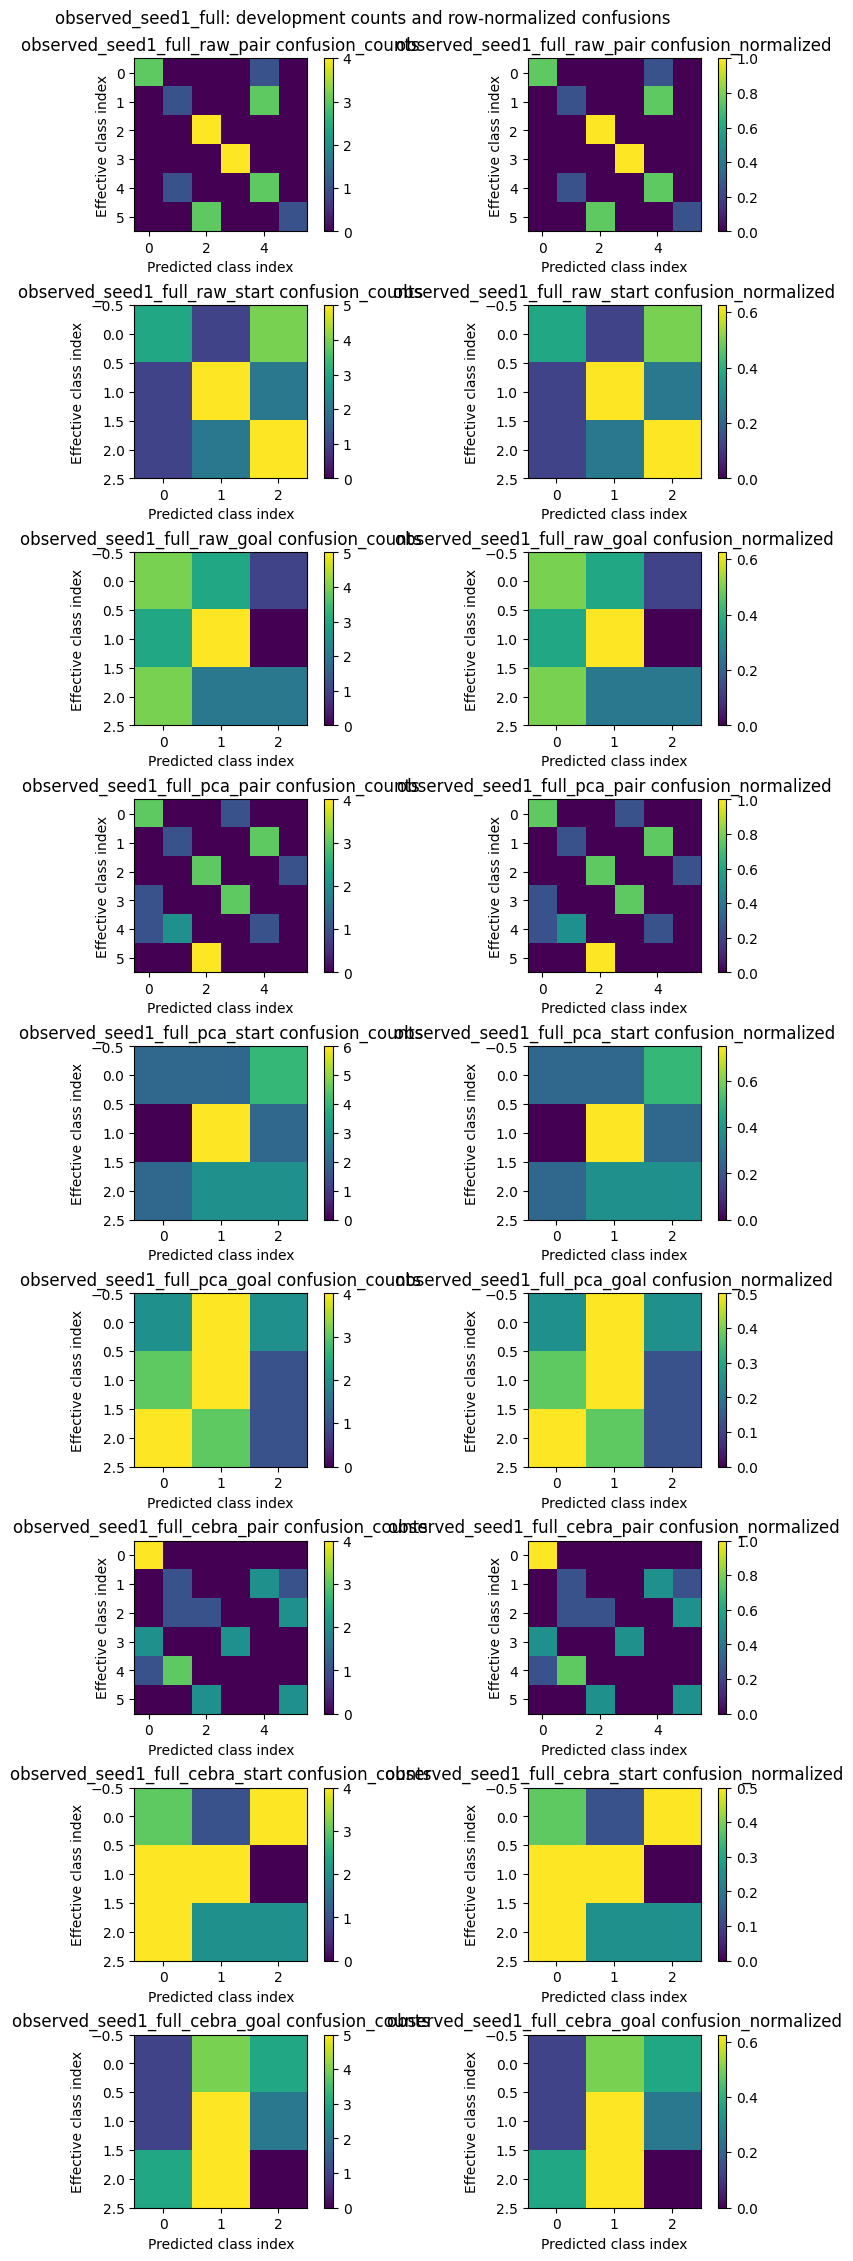

observed_seed1_reduced source accounting: {"eligible_sources": 72, "repeated_sources": 48, "reuse_histogram": {"0": 11, "1": 13, "2": 24, "3": 13, "4": 11}, "unused_sources": 11, "used_sources": 61}


[{"accuracy": 0.5833333333333334, "development_BA": 0.5833333333333334, "head": "pair", "log_loss": 1.437835607332568, "macro_F1": 0.5053391053391053, "name": "observed_seed1_reduced_raw_pair", "train_BA": 1.0, "train_development_gap": 0.41666666666666663}, {"accuracy": 0.625, "development_BA": 0.625, "head": "start", "log_loss": 0.9939539517148978, "macro_F1": 0.6145667198298777, "name": "observed_seed1_reduced_raw_start", "train_BA": 0.9791666666666666, "train_development_gap": 0.35416666666666663}, {"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": "goal", "log_loss": 0.9473632498074963, "macro_F1": 0.5185185185185185, "name": "observed_seed1_reduced_raw_goal", "train_BA": 0.9791666666666666, "train_development_gap": 0.4375}, {"accuracy": 0.4166666666666667, "development_BA": 0.4166666666666667, "head": "pair", "log_loss": 1.566688956403904, "macro_F1": 0.3444444444444444, "name": "observed_seed1_reduced_pca_pair", "train_BA": 1.0, "train_development_gap"

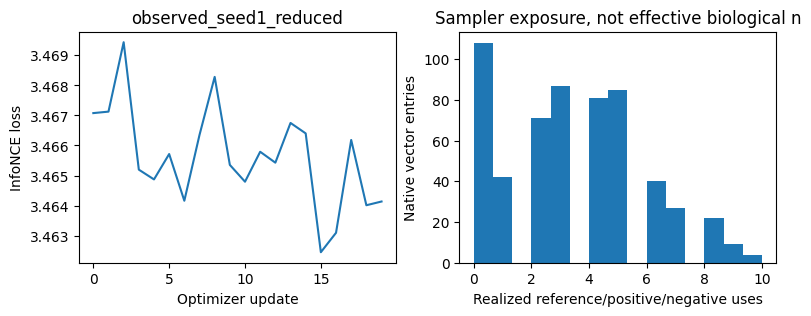

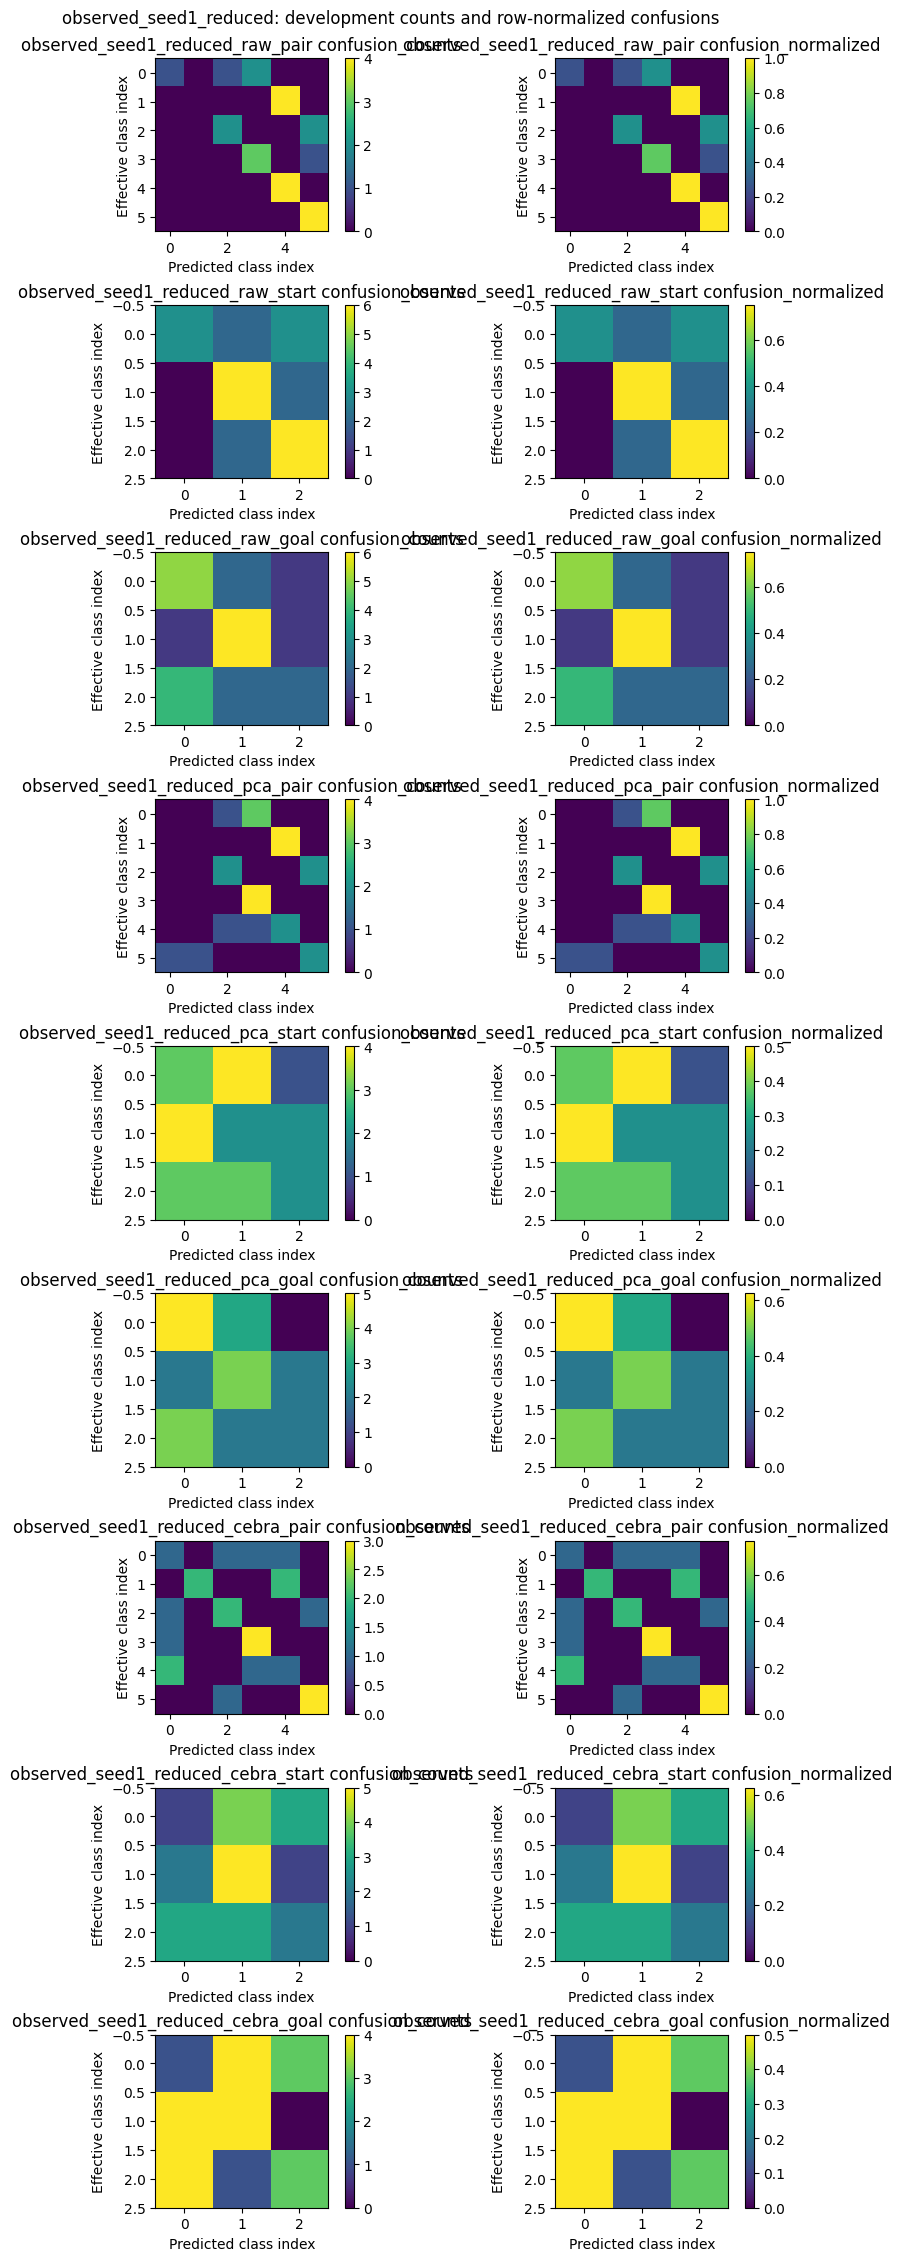

permuted_seed0_full source accounting: {"eligible_sources": 144, "repeated_sources": 41, "reuse_histogram": {"0": 49, "1": 54, "2": 34, "3": 6, "4": 1}, "unused_sources": 49, "used_sources": 95}


[{"accuracy": 0.2916666666666667, "development_BA": 0.2916666666666667, "head": "pair", "log_loss": 1.7460715382414367, "macro_F1": 0.27499999999999997, "name": "permuted_seed0_full_raw_pair", "train_BA": 0.9583333333333334, "train_development_gap": 0.6666666666666667}, {"accuracy": 0.375, "development_BA": 0.375, "head": "start", "log_loss": 1.1391230263294805, "macro_F1": 0.3707516339869281, "name": "permuted_seed0_full_raw_start", "train_BA": 0.9375, "train_development_gap": 0.5625}, {"accuracy": 0.5416666666666666, "development_BA": 0.5416666666666666, "head": "goal", "log_loss": 1.054765556465555, "macro_F1": 0.4444444444444444, "name": "permuted_seed0_full_raw_goal", "train_BA": 0.9375, "train_development_gap": 0.39583333333333337}, {"accuracy": 0.375, "development_BA": 0.375, "head": "pair", "log_loss": 1.749349914281466, "macro_F1": 0.3489417989417989, "name": "permuted_seed0_full_pca_pair", "train_BA": 0.875, "train_development_gap": 0.5}, {"accuracy": 0.4166666666666667, "dev

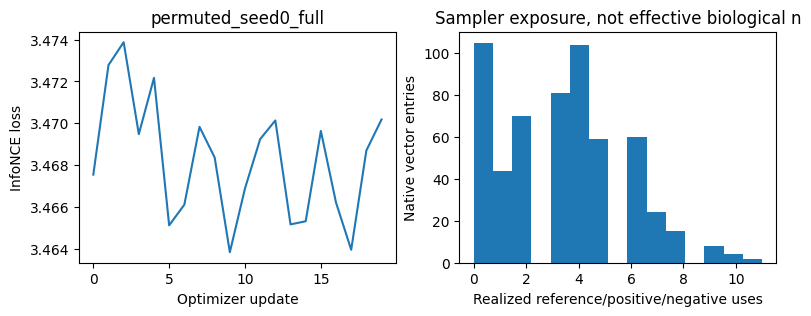

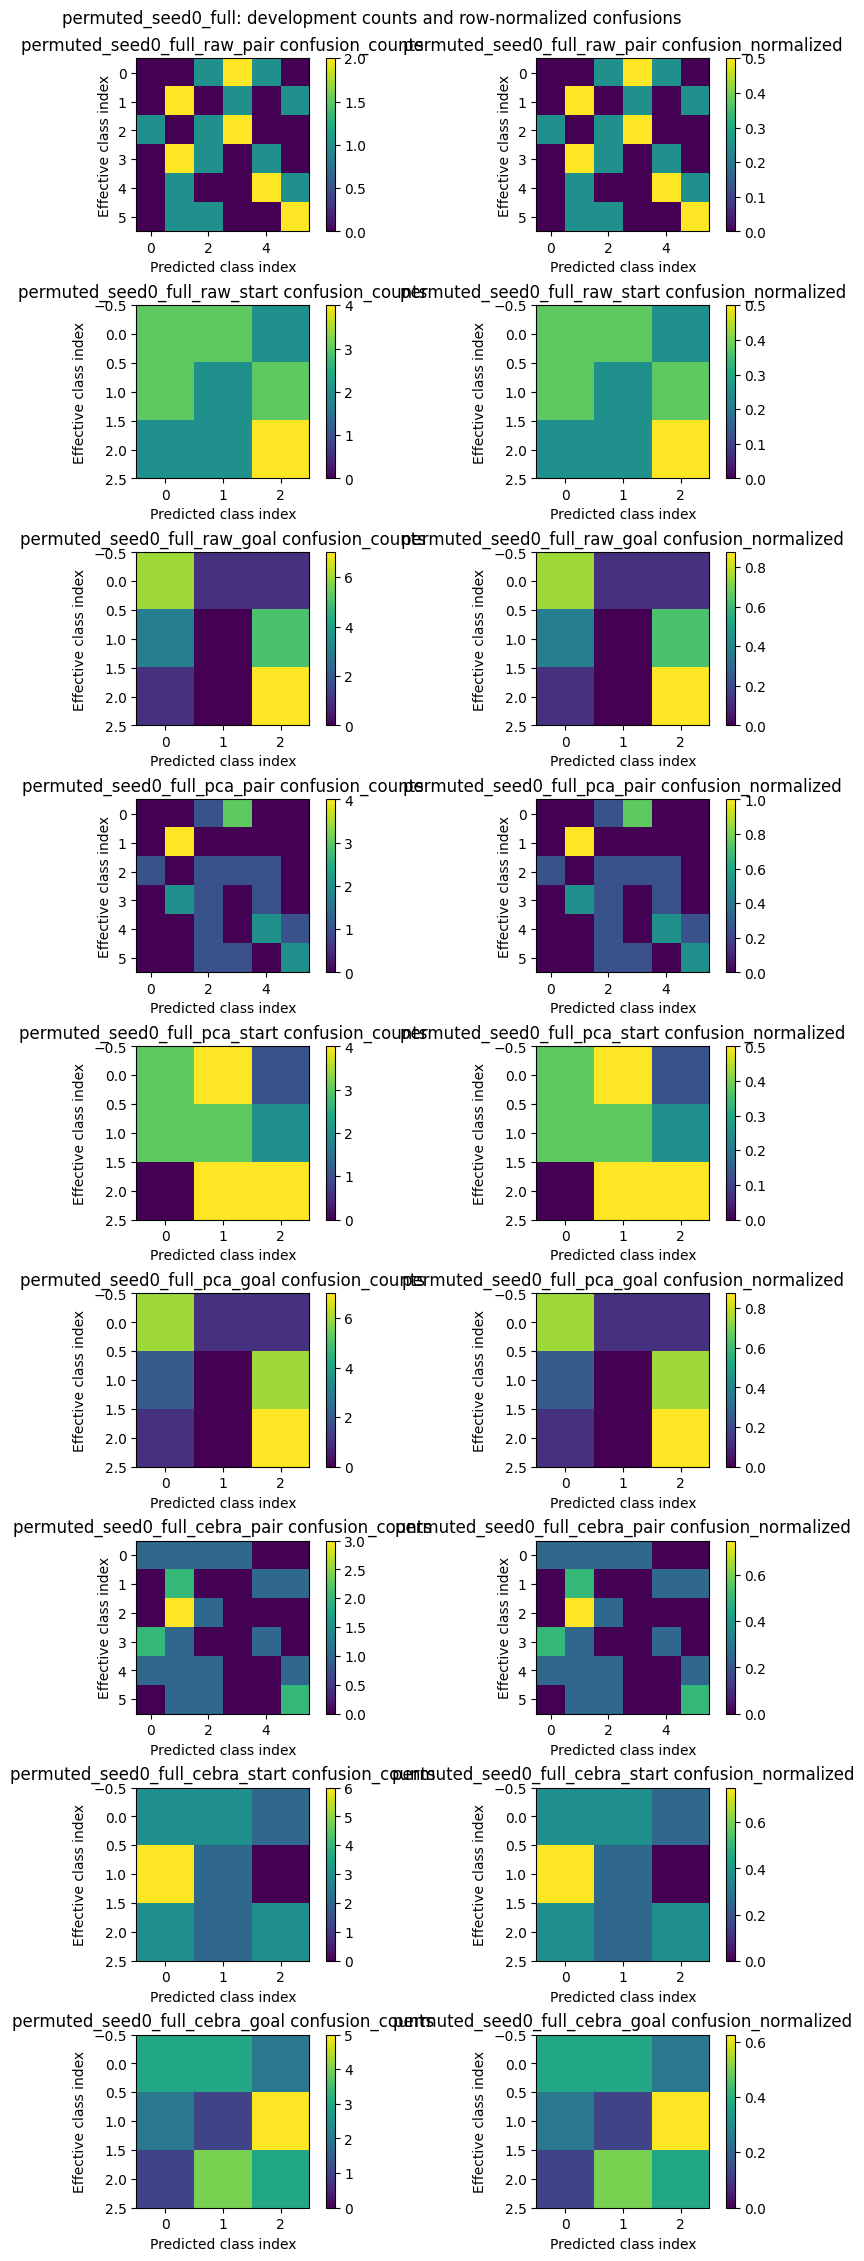

permuted_seed0_reduced source accounting: {"eligible_sources": 72, "repeated_sources": 45, "reuse_histogram": {"0": 5, "1": 22, "2": 19, "3": 21, "4": 4, "5": 1}, "unused_sources": 5, "used_sources": 67}


[{"accuracy": 0.4583333333333333, "development_BA": 0.4583333333333333, "head": "pair", "log_loss": 1.7662943477105681, "macro_F1": 0.3666666666666667, "name": "permuted_seed0_reduced_raw_pair", "train_BA": 0.9583333333333334, "train_development_gap": 0.5}, {"accuracy": 0.3333333333333333, "development_BA": 0.3333333333333333, "head": "start", "log_loss": 1.1967241776715498, "macro_F1": 0.336437908496732, "name": "permuted_seed0_reduced_raw_start", "train_BA": 0.9583333333333334, "train_development_gap": 0.625}, {"accuracy": 0.5, "development_BA": 0.5, "head": "goal", "log_loss": 1.1066963521757893, "macro_F1": 0.45263157894736844, "name": "permuted_seed0_reduced_raw_goal", "train_BA": 0.9791666666666666, "train_development_gap": 0.47916666666666663}, {"accuracy": 0.375, "development_BA": 0.375, "head": "pair", "log_loss": 1.7468305526265553, "macro_F1": 0.32356902356902356, "name": "permuted_seed0_reduced_pca_pair", "train_BA": 0.9791666666666666, "train_development_gap": 0.6041666666

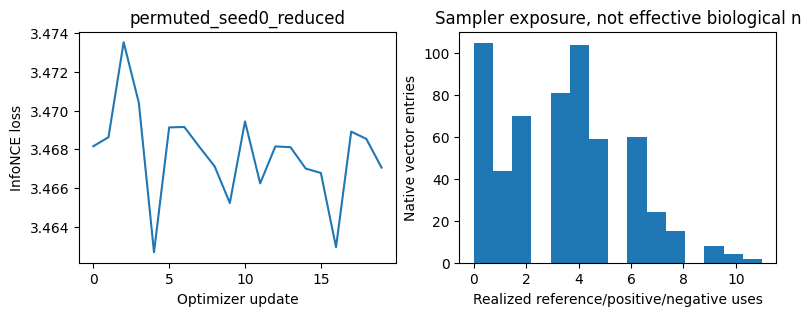

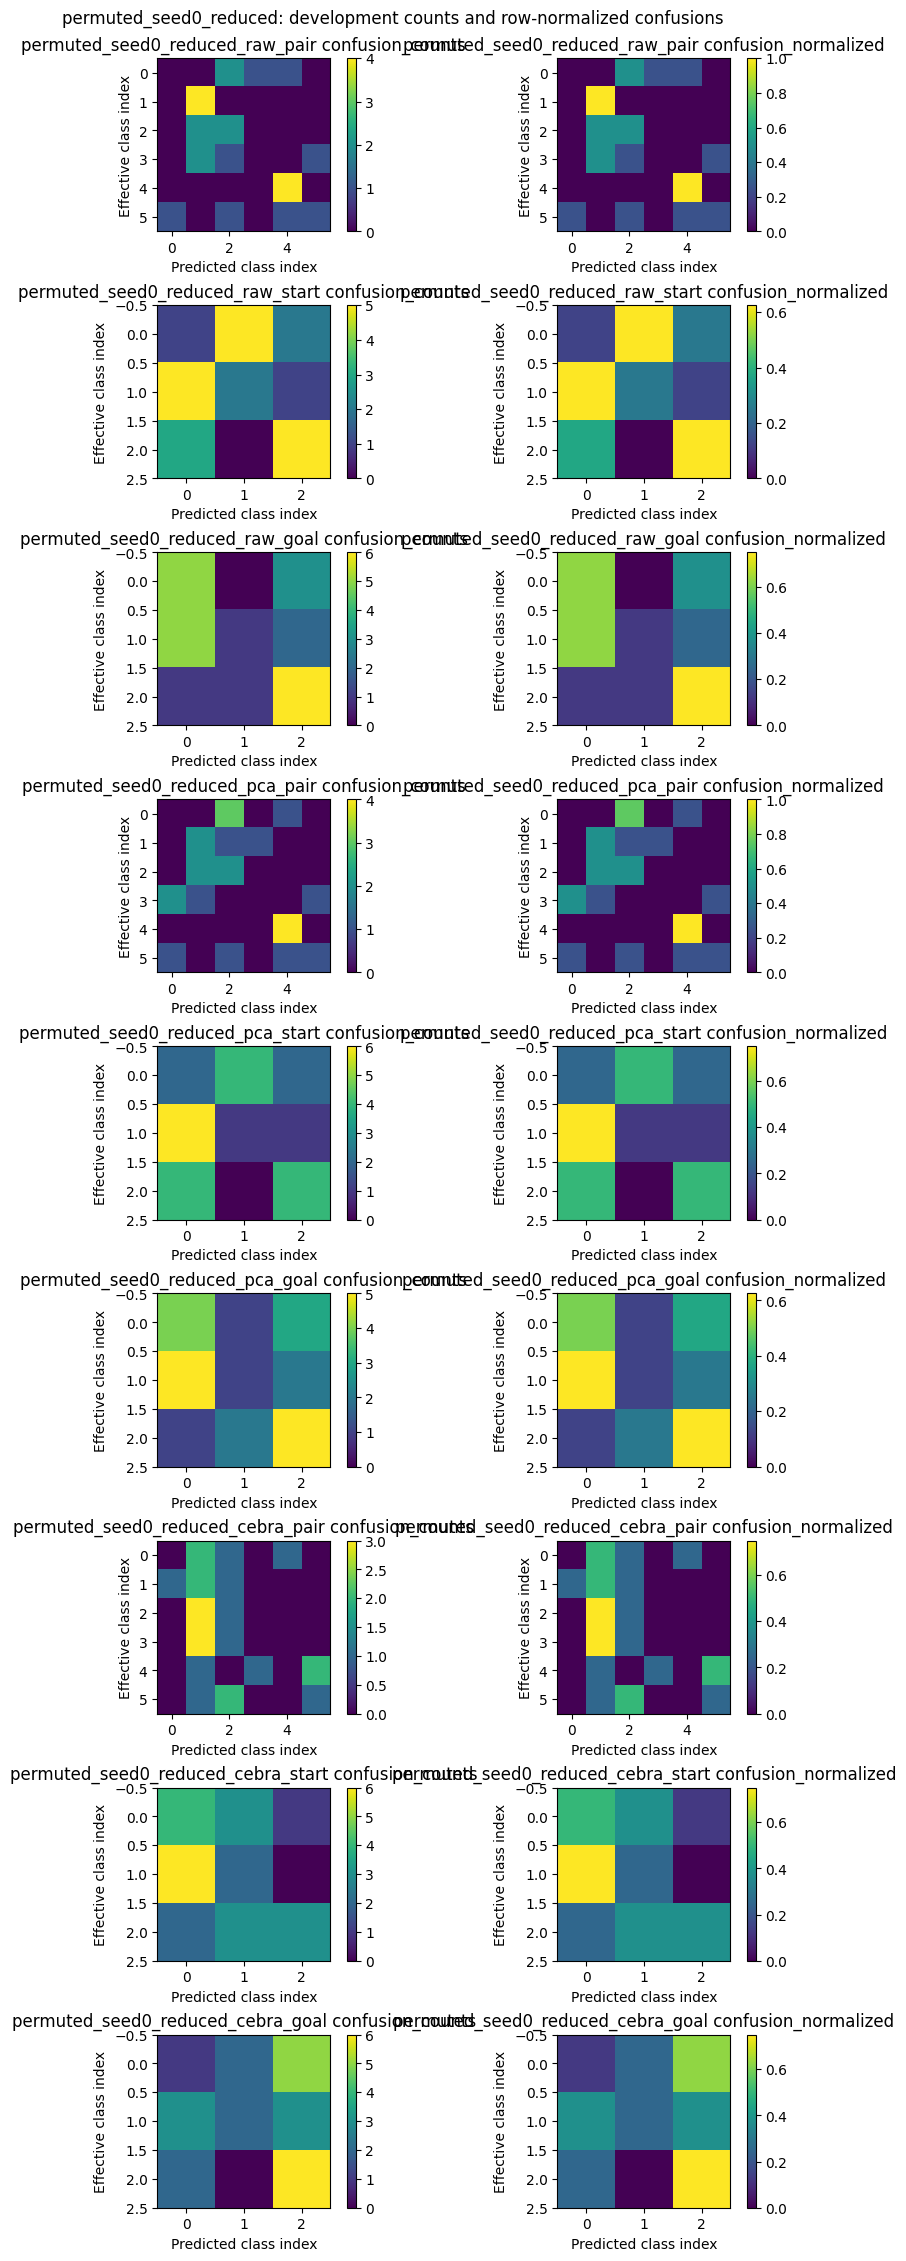

'aggregate_metrics.joblib'

In [5]:
for world in ('observed', 'permuted'):
    world_map = effective_pair_map(data, permutation_seed=None if world == 'observed' else settings['permutation_seed'])
    development_plan = sample_plan(data, split_id='development', rows_per_condition=settings['development_rows_per_condition'], seed=0, effective_conditions=world_map)
    reference_development = materialize(data, development_plan)
    store.save(world + '_fixed_development', reference_development)
    for seed in (settings['seeds'] if world == 'observed' else [0]):
        for budget in ('full', 'reduced'):
            selected, effective = source_budget(data, world_map, reduced=budget == 'reduced', subset_seed=settings['subset_seed'])
            train, development = checked_assemblies(selected, effective, development_plan, reference_development, config=settings, seed=seed)
            key = f'{world}_seed{seed}_{budget}'
            store.save_bundle(key, train, development)
            print(key, 'source accounting:', json.dumps(usage_summary(selected, train), sort_keys=True))
            standardizer = fit_standardizer(train.values)
            raw_train, raw_dev = raw_features(standardizer.transform(train.values)), raw_features(standardizer.transform(development.values))
            pca = fit_pca(train.values, n_components=settings['pca_components'])
            remaining = float(os.environ.get('NEURO_DEADLINE_MONOTONIC', time.monotonic() + 120)) - time.monotonic()
            encoder = cebra.fit(train.values, train.targets, iterations=settings['iterations'], batch_size=settings['batch_size'],
                                output_dimension=settings['output_dimension'], hidden=settings['hidden'], learning_rate=settings['learning_rate'],
                                seed=seed, max_seconds=remaining, device='cpu')
            store.save_encoder(key + '_raw', standardizer, kind='raw')
            store.save_encoder(key + '_pca', pca, kind='pca')
            store.save_encoder(key + '_cebra', encoder, kind='cebra')
            feature_pairs = {'raw': (raw_train, raw_dev), 'pca': (pca.transform(train.values), pca.transform(development.values)),
                             'cebra': (encoder.transform(train.values), encoder.transform(development.values))}
            run_results = []
            for representation, (train_x, dev_x) in feature_pairs.items():
                for head, y in target_heads(train).items():
                    model = fit_logistic(train_x, y, C=settings['logistic_C'], max_iter=settings['logistic_max_iter'])
                    row = store.readout(key + '_' + representation + '_' + head, model, encoder=key + '_' + representation,
                                        bundle=key, head=head, train_features=train_x, development_features=dev_x)
                    run_results.append(row)
            results.extend(run_results)
            print(json.dumps(compact_metrics(run_results), sort_keys=True))
            print('Realized sampler phase exposure:', encoder.diagnostics['exposure_summary']['reference_phase_counts'])
            assert len(encoder.diagnostics['loss']['total']) == settings['iterations']
            assert np.isfinite(encoder.diagnostics['loss']['total']).all()
            fig, axes = plt.subplots(1, 2, figsize=(9, 3))
            axes[0].plot(encoder.diagnostics['loss']['total']); axes[0].set(xlabel='Optimizer update', ylabel='InfoNCE loss', title=key)
            axes[1].hist(encoder.diagnostics['sample_exposure_counts'].reshape(-1), bins=15)
            axes[1].set(xlabel='Realized reference/positive/negative uses', ylabel='Native vector entries', title='Sampler exposure, not effective biological n')
            display(fig); plt.close(fig)
            fig = plot_confusions(run_results, title=key + ': development counts and row-normalized confusions')
            display(fig); plt.close(fig)
store.save('aggregate_metrics', results)

## Inspect transformed held-out coordinates
This descriptive plot does not establish neural-state dynamics or override matched readout scores.

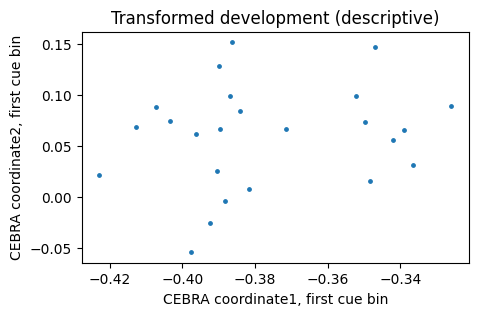

Grid summary: 6CEBRA,6PCA,54logistic; observed and permuted worlds are not pooled.


In [6]:
z = feature_pairs['cebra'][1]
fig, ax = plt.subplots(figsize=(5, 3)); ax.scatter(z[:, 0], z[:, 1], s=6)
ax.set(xlabel='CEBRA coordinate1, first cue bin', ylabel='CEBRA coordinate2, first cue bin', title='Transformed development (descriptive)')
display(fig); plt.close(fig)
print('Grid summary: 6CEBRA,6PCA,54logistic; observed and permuted worlds are not pooled.')

## Interpretation limits
These are source-safe conditional pseudopopulations, not simultaneous trials. Matching uses known labels; this is not an unknown-trial prediction pipeline. Bins, synthetic rows and computational seeds are dependent. Place-selected units, provisional marker meaning, inherited preprocessing and historical exposure remain limitations. Contributor separation does not remove long-range serial/session confounds. No biological confidence intervals, p-values, mechanism, dynamics or prospective-path claim follows from these figures. The permutation diagnostic is alignment-breaking, not a biological exchangeability test.

In [7]:
fit_counts = accounting.stop()
store.save('kernel_runtime_final', runtime_identity())
expected_counts = {'pca': 6, 'logistic': 54, 'lda': 0, 'cebra': 6, 'optimizer_updates': 6 * settings['iterations']}
manifest_hash = store.finish(fit_counts=fit_counts, expected_counts=expected_counts)
replay = verify_artifacts(output / 'artifacts', expected_manifest_hash=manifest_hash)
write_private_json(output / 'completion.json', {'manifest_sha256': manifest_hash, 'fit_counts': fit_counts, 'replay': replay})
print(json.dumps(replay, sort_keys=True))
assert replay['status'] == 'fit-blocked-loaded-model-replay-passed'

{"fit_counts": {"cebra": 6, "lda": 0, "logistic": 54, "optimizer_updates": 120, "pca": 6}, "manifest_sha256": "8f827ff9a441f1cac4e139b24279cec2ec448808170e0c4b306471515b28c113", "readout_splits_checked": 108, "status": "fit-blocked-loaded-model-replay-passed"}
